# DS 3000 Project Phase II: Proof of Concept

Your Names: Reyna Ahuja, Lea Choe, Isaac Song Hwang

Due: Thursday Nov 5 @ 11:59 PM EST

### Submission Instructions
Submit this `ipynb` file to Gradescope (this can also be done via the assignment on Canvas).  To ensure that your submitted `ipynb` file represents your latest code, make sure to give a fresh `Kernel > Restart & Run All` just before uploading the `ipynb` file to gradescope. **In addition:**
- Make sure your name is entered above
- Make sure you comment your code effectively
- If problems are difficult for the TAs/Profs to grade, you will lose points

### Tips for success
- Start early
- Make use of Discord
- Make use of Office Hours
- Remember to use cells and headings to make the notebook easy to read (if a grader cannot find the answer to a problem, you will receive no points for it)
- Under no circumstances may one student view or share their ungraded homework or quiz with another student [(see also)](http://www.northeastern.edu/osccr/academic-integrity), though you are welcome to **talk about** (*not* show each other your answers to) the problems.

### 1. (20 pts) Expresses the central motivation of the project and explains the (at least) two key questions to be explored. Gives a summary of the data processing pipeline so a technical expert can easily follow along.

*Adverse drug events (ADEs) occur when medications cause harm to individuals, and they are a serious public health threat that have caused more than 1.5 million emergency-department visits every year. Older adults (65+ year olds) make up more than 600,000 of these visits each year because they often take more medicine as they age. Although many adverse events are reported, not every report has the same severity. Some reports involve relatively less serious outcomes while others are defined by the FDA as serious adverse events, meaning they include hospitalization, disability, death, and other important events requiring intervention to prevent serious harm. This data science project may provide helpful insights by studying how patient and medication characteristics correlate with the seriousness of these reports to identify patterns associated with more severe outcomes.*
*The two key questions of interest include the following:*
1. *What patient and medication characteristics are associated with whether an adverse-event report is classified as serious versus non-serious?*
2. *Can these characteristics be used to predict whether an adverse-event report will involve hospitalization?*

*The data used to complete this project will be collected from the FDA Adverse Event Reporting System through the openFDA Drug Adverse Event API. In this API, each observation is one adverse-event report and includes patient demographic information, medication(s) involved, reactions reported, and seriousness of the ADE. To load the data, we will collect it directly in Python using the requests library, which returns JSON-formatted data. We will retrieve 999 records and extract patient age, sex, number of drugs, number of reactions, seriousness, and hospitalization status into a pandas DataFrame. We will then convert the numerical variables (age, number of drugs, and number of reactions) to numeric data types and the categorical variables (sex, seriousness, and hospitalization status) to categorical data types. We will also check for missing values and clean the data as needed before conducting our analysis.*

### 2. (25 pts) Obtains, cleans, and merges all data sources involved in the project.

In [8]:
import requests
import pandas as pd

url = "https://api.fda.gov/drug/event.json?limit=999"

response = requests.get(url)
data = response.json()

reports = data["results"]

In [9]:
# Store report data
rows = []

for report in reports:
    patient = report.get("patient", {})
    drugs = patient.get("drug", [])
    reactions = patient.get("reaction", [])
    
    rows.append({
        "age": patient.get("patientonsetage"),
        "sex": patient.get("patientsex"),
        "serious": report.get("serious"),
        "hospitalization": "1" if report.get("seriousnesshospitalization") == "1" else "0",
        "num_drugs": len(drugs),
        "num_reactions": len(reactions)
    })

# Create DataFrame
df = pd.DataFrame(rows)

# Convert numerical variables
df["age"] = pd.to_numeric(df["age"], errors="coerce")
df["num_drugs"] = pd.to_numeric(df["num_drugs"])
df["num_reactions"] = pd.to_numeric(df["num_reactions"])

# Convert categorical variables
df["sex"] = df["sex"].astype("category")
df["serious"] = df["serious"].astype("category")
df["hospitalization"] = df["hospitalization"].astype("category")

# Check the data
print("Number of observations:", len(df))
print("Data types:", df.dtypes)
print("Unique values for serious:", df["serious"].value_counts())
print("Unique values for hospitalization:", df["hospitalization"].value_counts())

# Remove rows with any missing values
print("Rows before:", len(df))
df = df.dropna()
print("Rows after:", len(df))

df.head()

Number of observations: 999
Data types: age                 float64
sex                category
serious            category
hospitalization    category
num_drugs             int64
num_reactions         int64
dtype: object
Unique values for serious: 2    545
1    454
Name: serious, dtype: int64
Unique values for hospitalization: 0    828
1    171
Name: hospitalization, dtype: int64
Rows before: 999
Rows after: 657


,age,sex,serious,hospitalization,num_drugs,num_reactions
0,26.0,1,1,0,1,2
1,77.0,2,1,0,1,4
5,48.0,2,2,0,6,1
6,68.0,2,2,0,2,2
7,65.0,2,2,0,3,1


### 3. (25 pts) Builds at least two visualizations (graphs/plots) from the data which help to understand or answer the questions of interest. These visualizations will be graded based on how much information they can effectively communicate to readers. Please make sure your visualization are sufficiently distinct from each other.

A grouped bar graph that shows proportion of serious adverse drug events by age and patient sex can show how patient characteristics are associated with the degree of adverse drug event.  The first visualization does just this, showing a simple trend of proportion of adverse drug events that are considered serious by age group and sex. 

A heatmap of number of drugs involved, age group, and hospitalization rate is a more indepth visualization of how these different characteristics come together to show story of adverse drug events as tracked by the FDA. This visualization shows how hospitalizations by age group and number of drugs involved in a way that a simple bar graph is unable to. It gives a better idea of how these characterisics could be potentially be used to predict the outcome of an adverse drug event; wheter it will end in hospialtization or not. 

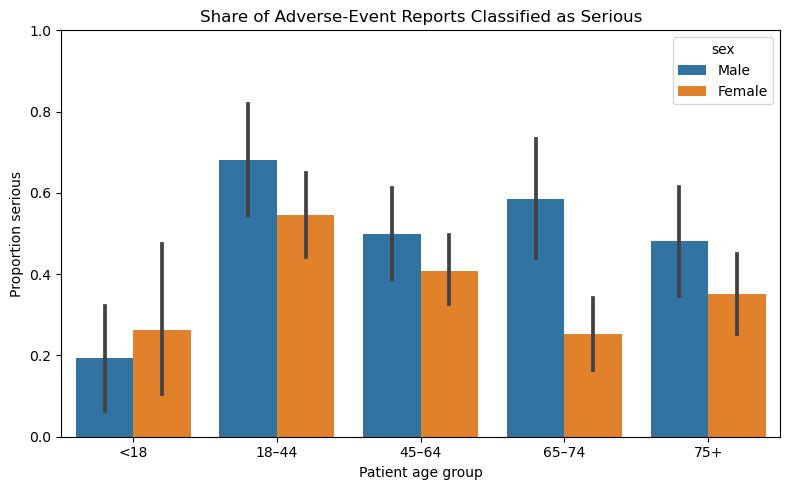

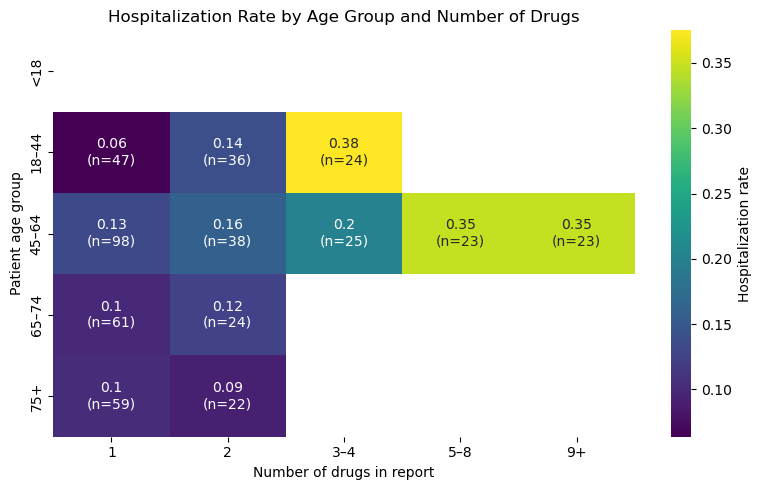

In [28]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Prepare data for plotting (df is your cleaned DataFrame)
plot_df = df.copy()

# Keep only known sex values ("0" = unknown) and plausible ages
plot_df = plot_df[plot_df["sex"].isin(["1", "2"])]
plot_df = plot_df[(plot_df["age"] >= 0) & (plot_df["age"] <= 120)]

# Readable labels
plot_df["sex"] = plot_df["sex"].map({"1": "Male", "2": "Female"})

# Numeric 0/1 versions so we can take averages (rates)
plot_df["serious_flag"] = (plot_df["serious"] == "1").astype(int)
plot_df["hosp_flag"] = (plot_df["hospitalization"] == "1").astype(int)

# Groupings
plot_df["age_group"] = pd.cut(plot_df["age"], bins=[0, 18, 45, 65, 75, 121],
                              labels=["<18", "18–44", "45–64", "65–74", "75+"],
                              right=False)
plot_df["drug_group"] = pd.cut(plot_df["num_drugs"], bins=[0, 1, 2, 4, 8, np.inf],
                               labels=["1", "2", "3–4", "5–8", "9+"])

# Plot 1: serious-report rate by age group and sex
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=plot_df, x="age_group", y="serious_flag", hue="sex",
            errorbar=("ci", 95), ax=ax)
ax.set_title("Share of Adverse-Event Reports Classified as Serious")
ax.set_xlabel("Patient age group")
ax.set_ylabel("Proportion serious")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

# Plot 2: hospitalization rate heatmap with sample sizes
rate = plot_df.pivot_table(index="age_group", columns="drug_group",
                           values="hosp_flag", aggfunc="mean", observed=True)
n = plot_df.pivot_table(index="age_group", columns="drug_group",
                        values="hosp_flag", aggfunc="size", observed=True)
labels = rate.round(2).astype(str) + "\n(n=" + n.astype(str) + ")"
rate_masked = rate.where(n >= 20)  # hide cells with too few reports

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(rate_masked, annot=labels, fmt="", cmap="viridis", ax=ax,
            cbar_kws={"label": "Hospitalization rate"})
ax.set_title("Hospitalization Rate by Age Group and Number of Drugs")
ax.set_xlabel("Number of drugs in report")
ax.set_ylabel("Patient age group")
plt.tight_layout()
plt.show()

### 4. (20 pts) Develop at least two functions that will verify fit or other attributes of analysis from a ML model. (You don't need to identify a specific model yet).  Include markup sections which explain why these functions will be useful in analyzing a ML model.

### 5. (10 pts) Discuss potential ethical implications of the data and using ML to analyze it.

*Similar to Flock cameras, there are ethical concerns when using Machine Learning to handle personal patient information. Even though we are intending this project to help reduce the risk of serious ADE's for patients in the future, it is always possible that when we release the technology to the public, it can cause unintended or harmful consequences. One concern that a lot of people could have is that we are using personal patient information such as patient age, sex, medications, hospitalization, and ADE's. Possible bias or discrimination that this could lead to includes classifying certain groups as higher risk, potentially affecting how healthcare providers or insurance companies treat these patients. Moreover, not all ADE's are reported to the FDA, and we also removed reports that had missing information (such as 300+ rows missing patient ages) which could lead to inaccurate predictions that could not represent the entire population. Thus, when handling patient data using machine learning, we need to consider how it can improve drug safety as well as negatively affect future patients in a holistic manner.*